In [1]:
# =============================================================================
# CELL 0 -- Configuration, imports and style
#
# Sensitivity study for the two "tuning knobs" of the HCD isolation pipeline
# (Sect. 2.3 of the draft) that are NOT physically derived quantities:
#
#   halo_radius_cut  -- half-width, in units of R200, of the window used to
#                        decide whether a basin's dominant cell is close
#                        enough to the halo to be associated with it (the
#                        "+/-5 R200" aperture). Production default: 5.0.
#                        Only affects ACCEPTANCE, not segmentation: it never
#                        changes which basins the watershed finds, only
#                        whether a given basin is allowed to become an HCD.
#
#   hcd_peak_contrast (R in the draft's notes) -- the peak-persistence
#                        contrast used by the watershed: two adjacent peaks
#                        are merged into one basin whenever the saddle
#                        between them exceeds R times the weaker peak.
#                        Production default: 0.5. Unlike halo_radius_cut,
#                        this DOES change the segmentation itself -- it can
#                        turn two basins into one or vice versa.
#
# This notebook reads fake_spectra_fork/ for reference only and never edits
# it, and it does not touch 01_ or 01.5_. It finds ONE sightline (with the
# same multi-basin search as 01.5_, so it likely lands on the same kind of
# case) and reruns it across a grid of values for each parameter in turn,
# holding the other one at its production value, to see whether the accepted
# HCD set (which basins, how much N_HI) is stable around the production
# choice or would change materially with a different, still-defensible pick.
# =============================================================================
%matplotlib widget

import os
import sys
from contextlib import contextmanager

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

REPO_DIR = os.path.abspath("..")          # notebooks_TNG/ -> FakeSpectra_DLAs/
sys.path.insert(0, os.path.join(REPO_DIR, "tools"))

import utils
import radii_skewers
from fake_spectra import spectra

if not hasattr(spectra, "HCD_ALGORITHMS"):
    raise ImportError(f"{spectra.__file__} is not the HCD fork "
                      "(no HCD_ALGORITHMS)")
print("using:", spectra.__file__)
print("algorithms:", spectra.HCD_ALGORITHMS)

# --- simulation --------------------------------------------------------------
SIM_NAME  = "TNG50-2"
BASE_PATH = f"/home/STORAGE/{SIM_NAME}"
SNAP_NUM  = 25                            # z ~ 3.01
SIM_TYPE  = "TNG"
RES_KMS   = 10.0                          # production sampling; not swept here

HCD_ALGORITHM = "peaks+blend"
KERNEL = "tophat"

# --- production (baseline) values of the two parameters under test ----------
HALO_RADIUS_CUT_PROD = 5.0     # +/- R200, Sect. 2.4 of the draft
PEAK_CONTRAST_PROD   = 0.5     # R, Sect. 2.3 of the draft

# --- sweep grids ---------------------------------------------------------
# halo_radius_cut only gates ACCEPTANCE (real-space window), so a wide grid
# from "very tight" to "essentially unbounded" is cheap and informative; the
# production value is included explicitly.
HALO_RADIUS_CUT_GRID = np.array([0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0,
                                 15.0, 20.0, 30.0, 50.0])

# hcd_peak_contrast changes the SEGMENTATION itself, so we sample the full
# open interval (0, 1) at a resolution fine enough to see where the basin
# count changes; the production value is included explicitly.
PEAK_CONTRAST_GRID = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])

# --- halo search (same recipe as 01.5_, to land on the same kind of case) ---
HALO_ID  = None        # None -> draw from the stratified pool
POSITION = None        # None -> random among Right/Left/Top/Bottom
SEED     = 12345

HALO_LOGM_RANGE = (11.5, 13.0)
N_CANDIDATES    = 60

# We want a sightline with real structure to sweep on -- a single, isolated
# DLA would make both sweeps look trivially flat. Same criterion as 01.5_.
REQUIRE_MULTI_BASIN = True
MIN_BASINS_FOR_TEST = 2

NUM_PARAM_IMPACTS = 30
RANGE_PARAM_IMPACTS = (0.01, 50.0)
HCD_LOG_NHI = 17.2

AXIS      = 1              # 1-indexed, as fake_spectra expects (1 = x)
B_TARGET  = 0.5             # snapped to the nearest production grid value

PLOT_DIR = os.path.join(REPO_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)
rng = np.random.default_rng(SEED)

# --- style -------------------------------------------------------------------
plt.rc('font', family='serif', size=16)
plt.rcParams.update({
    "mathtext.fontset": "cm", "text.usetex": False,
    "axes.linewidth": 1.6, "axes.grid": False,
    "axes.labelsize": 19, "legend.fontsize": 15,
    "xtick.labelsize": 16, "ytick.labelsize": 16,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 8, "ytick.major.size": 8,
    "xtick.minor.size": 4, "ytick.minor.size": 4,
    "xtick.major.width": 1.4, "ytick.major.width": 1.4,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "legend.frameon": True, "legend.framealpha": 0.92,
    "figure.dpi": 72, "savefig.dpi": 300, "savefig.bbox": "tight",
})

colors = [
    "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2",
    "#D55E00", "#CC79A7", "#000000", "#999999", "#553388",
]
OI = {"orange": colors[0], "sky": colors[1], "green": colors[2],
      "yellow": colors[3], "blue": colors[4], "vermillion": colors[5],
      "purple": colors[6], "black": colors[7], "grey": colors[8],
      "violet": colors[9]}
plt.rcParams["axes.prop_cycle"] = mpl.cycler(color=colors)


using: /home/vroberto/fake_spectra_fork/fake_spectra/spectra.py
algorithms: ('peaks', 'peaks+blend', 'region_growing')


In [2]:
# =============================================================================
# CELL 1 -- Silence the C interpolator's progress printing
#
# We are about to build dozens of Spectra objects (one per candidate halo,
# one per grid point in each sweep); without this the notebook would be
# unreadable.
# =============================================================================
@contextmanager
def suppress_c_stdout():
    sys.stdout.flush()
    saved = os.dup(1)
    devnull = os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(devnull, 1)
        yield
    finally:
        os.dup2(saved, 1)
        os.close(devnull)
        os.close(saved)


In [3]:
# =============================================================================
# CELL 2 -- Impact-parameter grid, halo selection, sightline construction
#
# Identical machinery to 01.5_'s Cell 2; kept here so this notebook can find
# a sightline on its own without depending on another notebook's state.
# =============================================================================
def build_r_multipliers(n_impacts, impact_min, impact_max):
    return np.insert(np.logspace(np.log10(impact_min), np.log10(impact_max),
                                 n_impacts), 0, 0.0)


R_MULTIPLIERS = build_r_multipliers(NUM_PARAM_IMPACTS, *RANGE_PARAM_IMPACTS)


def snap_impact(b_target, grid=R_MULTIPLIERS):
    pos = grid[grid > 0]
    k = int(np.argmin(np.abs(np.log10(pos) - np.log10(b_target))))
    return float(pos[k]), k


B_USED, B_INDEX = snap_impact(B_TARGET)
print(f"impact parameter: {B_TARGET} -> {B_USED:.4f} R200 (grid index {B_INDEX})")

ctx = utils.SimulationContext(BASE_PATH, SNAP_NUM, sim_type=SIM_TYPE)
finder = utils.HaloFinder(ctx)

for _p in (os.path.join(BASE_PATH, f"groups_{SNAP_NUM:03d}",
                        f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5"),
           os.path.join(BASE_PATH, f"snapdir_{SNAP_NUM:03d}")):
    if not os.path.exists(_p):
        raise FileNotFoundError(f"not found: {_p}\nCheck BASE_PATH={BASE_PATH!r}")

if HALO_ID is None:
    import run_parallel_illustris as rpi
    lo, hi = HALO_LOGM_RANGE
    candidates, total_halos, _ = rpi.get_stratified_halo_indices(
        BASE_PATH, SNAP_NUM, [(lo, hi)], N_CANDIDATES, 0, SEED)
    candidates = np.asarray(candidates, dtype=int).ravel()
    print(f"{len(candidates)} candidates in log10 M200 = [{lo}, {hi}] "
          f"({total_halos:,} haloes in the catalogue)")
else:
    candidates = np.array([HALO_ID], dtype=int)

POSITION_TAGS = ("Right", "Left", "Top", "Bottom")
position = POSITION if POSITION is not None else str(rng.choice(POSITION_TAGS))
print(f"sightline: axis {AXIS} (1 = x), position {position}")


def sightline_for(halo_info, axis_1indexed, b_mult, tag):
    g = radii_skewers.SkewerGeometry(ctx, halo_info)
    for sk in g.generate_skewers(r_multiplier=b_mult):
        if sk['axis'] == axis_1indexed - 1 and sk['position_tag'] == tag:
            cofm = np.mod(np.asarray(halo_info['cm'], float) + sk['offset_vec'],
                          halo_info['box_size'])
            return (np.array([cofm], dtype=np.float64),
                    np.array([axis_1indexed], dtype=np.int32), sk)
    raise RuntimeError(f"no skewer with axis={axis_1indexed}, tag={tag}")


impact parameter: 0.5 -> 0.4552 R200 (grid index 13)
Scanning 1,361,174 halos across 128 catalog chunk(s)...
  h = 0.6774, converting bins to code units (10^10 M_sun/h)

--- Mass Stratification (seed=12345, h=0.6774, sim=TNG50-2) ---
  Bin [10^11.5 - 10^13.0] M_sun :    251 available ->   60 drawn  
60 candidates in log10 M200 = [11.5, 13.0] (1,361,174 haloes in the catalogue)
sightline: axis 1 (1 = x), position Top


In [4]:
# =============================================================================
# CELL 3 -- Find a multi-basin sightline, and the helper the sweeps reuse
#
# run_hcd_only takes halo_radius_cut and hcd_peak_contrast as EXPLICIT
# arguments (both already keyword args of spectra.Spectra) so the same
# function drives the search below and the two sweeps that follow, always on
# the exact same (cofm, axis) sightline. Only the HCD_only pass is needed:
# hcd_basin_info carries peak_kms, N_HI, in_window and accepted for every
# basin, which is everything both sweeps need to report.
# =============================================================================
def run_hcd_only(halo_info, cofm, axis_arr, halo_radius_cut, hcd_peak_contrast,
                 res_kms=RES_KMS):
    with suppress_c_stdout():
        ss = spectra.Spectra(
            int(SNAP_NUM), BASE_PATH, cofm=cofm, axis=axis_arr,
            res=res_kms, savefile=f"unused_{halo_info['id']}_sens.hdf5",
            reload_file=True, kernel=KERNEL, MPI=None, quiet=True,
            filter_mode="HCD_only", hcd_algorithm=HCD_ALGORITHM,
            units=ctx.units, halo_r200=float(halo_info['r200']),
            halo_radius_cut=halo_radius_cut,
            hcd_peak_contrast=hcd_peak_contrast,
            **utils.SPECTRA_GAS_KWARGS)    # same star-forming gas model as the pipeline
        tau = ss.get_tau("H", 1, 1215)[0]
        colden = ss.get_col_density("H", 1)[0]
    basins = list(getattr(ss, "hcd_basin_info", {}).get(0, []))
    accepted = [b for b in basins if b['accepted']]
    return dict(colden_tot=float(colden.sum()), basins=basins,
                n_basins=len(basins), n_accepted=len(accepted),
                accepted_nhi=float(sum(b['N_HI'] for b in accepted)))


res = halo_info = sk_info = cofm = axis_arr = None
fallback = None
for hid in candidates:
    hi_info = finder.get_halo_properties(int(hid))
    cf, ax_arr, sk = sightline_for(hi_info, AXIS, B_USED, position)
    r = run_hcd_only(hi_info, cf, ax_arr, HALO_RADIUS_CUT_PROD, PEAK_CONTRAST_PROD)
    has_hcd = r['colden_tot'] > 0 and np.log10(r['colden_tot']) >= HCD_LOG_NHI
    print(f"halo {int(hid)}  log10 M200 = "
          f"{np.log10(hi_info['mass'] * 1e10 / 0.6774):.2f}  "
          f"-> {r['n_basins']} basin(s), {r['n_accepted']} accepted, "
          f"{'HCD' if has_hcd else 'no HCD'}")

    if HALO_ID is not None:
        res, halo_info, sk_info, cofm, axis_arr = r, hi_info, sk, cf, ax_arr
        break

    if has_hcd and fallback is None:
        fallback = (r, hi_info, sk, cf, ax_arr)

    if has_hcd and (not REQUIRE_MULTI_BASIN or r['n_basins'] >= MIN_BASINS_FOR_TEST):
        res, halo_info, sk_info, cofm, axis_arr = r, hi_info, sk, cf, ax_arr
        print(f"--> using halo {int(hid)}: {r['n_basins']} basin(s), suitable "
              "for the sensitivity sweeps")
        break

if res is None and fallback is not None:
    res, halo_info, sk_info, cofm, axis_arr = fallback
    print("--> no multi-basin sightline found; falling back to the first "
          "sightline carrying a single HCD")

if res is None:
    raise RuntimeError("no candidate hosts an HCD here; widen HALO_LOGM_RANGE "
                       "or lower B_TARGET")

print(f"\nbaseline (production: window=+/-{HALO_RADIUS_CUT_PROD} R200, "
      f"R={PEAK_CONTRAST_PROD}):")
print(f"  halo {halo_info['id']}  log10 M200 = "
      f"{np.log10(halo_info['mass'] * 1e10 / 0.6774):.2f}  b = {B_USED:.4f} R200")
print(f"  {res['n_basins']} basin(s) found, {res['n_accepted']} accepted, "
      "log10 N_HI(accepted) = "
      f"{np.log10(res['accepted_nhi']) if res['accepted_nhi'] > 0 else -np.inf:.3f}")


halo 25  log10 M200 = 12.21  -> 22 basin(s), 2 accepted, HCD
--> using halo 25: 22 basin(s), suitable for the sensitivity sweeps

baseline (production: window=+/-5.0 R200, R=0.5):
  halo 25  log10 M200 = 12.21  b = 0.4552 R200
  22 basin(s) found, 2 accepted, log10 N_HI(accepted) = 19.727


In [5]:
# =============================================================================
# CELL 4 -- Sensitivity to the halo association window (+/- halo_radius_cut * R200)
#
# halo_radius_cut only decides ACCEPTANCE: it is applied to already-found
# basins (Sect. 2.3/2.4 of the draft), so the segmentation itself -- how many
# basins, where their peaks sit, how much N_HI each carries -- must be
# EXACTLY the same at every grid point. We check that explicitly below: if it
# is not, something about the window is leaking into the segmentation and the
# result should not be trusted. What SHOULD change with the window is which
# basins are "in_window" and therefore eligible to be accepted.
# =============================================================================
window_rows = [run_hcd_only(halo_info, cofm, axis_arr, w, PEAK_CONTRAST_PROD)
               for w in HALO_RADIUS_CUT_GRID]

n_basins_all = {r['n_basins'] for r in window_rows}
peaks_all = {tuple(round(b['peak_kms'], 3) for b in r['basins'])
             for r in window_rows}
if len(n_basins_all) == 1 and len(peaks_all) == 1:
    print(f"segmentation invariance check: OK -- all {HALO_RADIUS_CUT_GRID.size} "
          f"window values give the same {n_basins_all.pop()} basin(s) at the "
          "same peak velocities, as expected (the window only gates "
          "acceptance).\n")
else:
    print("segmentation invariance check: FAILED -- the basin list changed "
          "with halo_radius_cut, which should not happen; investigate before "
          "trusting the acceptance numbers below.\n")

print(f"{'window [R200]':>14s}  {'n_basins':>8s}  {'n_accepted':>10s}  "
      f"{'log10 N_HI(acc)':>16s}")
for w, r in zip(HALO_RADIUS_CUT_GRID, window_rows):
    logn = np.log10(r['accepted_nhi']) if r['accepted_nhi'] > 0 else -np.inf
    tag = "  <- production" if np.isclose(w, HALO_RADIUS_CUT_PROD) else ""
    print(f"{w:14.1f}  {r['n_basins']:8d}  {r['n_accepted']:10d}  "
          f"{logn:16.3f}{tag}")

acc_prod = next(r['n_accepted'] for w, r in zip(HALO_RADIUS_CUT_GRID, window_rows)
                if np.isclose(w, HALO_RADIUS_CUT_PROD))
stable = [w for w, r in zip(HALO_RADIUS_CUT_GRID, window_rows)
          if r['n_accepted'] == acc_prod]
print(f"\naccepted count stays at the production value ({acc_prod}) for window "
      f"in [{min(stable):.1f}, {max(stable):.1f}] R200 (out of the "
      f"[{HALO_RADIUS_CUT_GRID.min():.1f}, {HALO_RADIUS_CUT_GRID.max():.1f}] "
      "R200 grid tested).")


segmentation invariance check: OK -- all 12 window values give the same 22 basin(s) at the same peak velocities, as expected (the window only gates acceptance).

 window [R200]  n_basins  n_accepted   log10 N_HI(acc)
           0.5        22           0              -inf
           1.0        22           0              -inf
           2.0        22           1            19.727
           3.0        22           1            19.727
           4.0        22           1            19.727
           5.0        22           2            19.727  <- production
           7.0        22           2            19.727
          10.0        22           2            19.727
          15.0        22           3            19.727
          20.0        22           3            19.727
          30.0        22           3            19.727
          50.0        22           3            19.727

accepted count stays at the production value (2) for window in [5.0, 10.0] R200 (out of the [0.5, 50.0] R20

saved /home/vroberto/FakeSpectra_DLAs/plots/sensitivity_halo_radius_cut.png


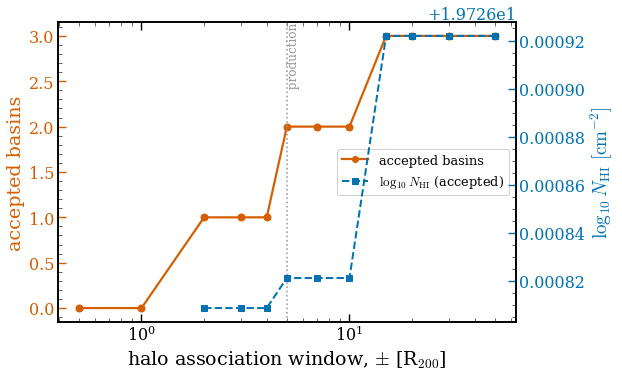

In [6]:
# =============================================================================
# CELL 5 -- FIG (plots/sensitivity_halo_radius_cut.png)
# =============================================================================
plt.close('all')
fig, ax1 = plt.subplots(figsize=(8.2, 5.4))
ax2 = ax1.twinx()

n_acc = [r['n_accepted'] for r in window_rows]
logn_acc = [np.log10(r['accepted_nhi']) if r['accepted_nhi'] > 0 else np.nan
            for r in window_rows]

ax1.plot(HALO_RADIUS_CUT_GRID, n_acc, 'o-', color=OI["vermillion"], lw=2.2,
         ms=7, label='accepted basins')
ax2.plot(HALO_RADIUS_CUT_GRID, logn_acc, 's--', color=OI["blue"], lw=2.0,
         ms=6, label=r'$\log_{10} N_{\rm HI}$ (accepted)')

ax1.axvline(HALO_RADIUS_CUT_PROD, color=OI["grey"], lw=1.6, ls=':')
ax1.text(HALO_RADIUS_CUT_PROD, ax1.get_ylim()[1], '  production', rotation=90,
         va='top', ha='left', fontsize=12, color=OI["grey"])

ax1.set_xscale('log')
ax1.set_xlabel(r'halo association window, $\pm$ [R$_{200}$]')
ax1.set_ylabel('accepted basins', color=OI["vermillion"])
ax2.set_ylabel(r'$\log_{10} N_{\rm HI}\ [\mathrm{cm^{-2}}]$', color=OI["blue"])
ax1.tick_params(axis='y', colors=OI["vermillion"])
ax2.tick_params(axis='y', colors=OI["blue"])

ax1.legend(
    [Line2D([], [], color=OI["vermillion"], marker='o', lw=2.2),
     Line2D([], [], color=OI["blue"], marker='s', lw=2.0, ls='--')],
    ['accepted basins', r'$\log_{10} N_{\rm HI}$ (accepted)'],
    loc='center right', fontsize=13)

ax1.grid(False)
for s in ax1.spines.values():
    s.set_linewidth(1.6)

out = os.path.join(PLOT_DIR, "sensitivity_halo_radius_cut.png")
fig.savefig(out, dpi=300, bbox_inches='tight')
if hasattr(fig.canvas, "header_visible"):
    fig.canvas.header_visible = False
print(f"saved {out}")
plt.show()


In [7]:
# =============================================================================
# CELL 6 -- Sensitivity to the peak-persistence contrast R (hcd_peak_contrast)
#
# Unlike halo_radius_cut, R changes the SEGMENTATION itself (Sect. 2.3): it is
# the fraction of the weaker of two adjacent peaks that the saddle between
# them must reach for the two to be kept apart. A larger R merges more
# aggressively (fewer, broader basins); a smaller R keeps more structure
# separate (more, narrower basins). We hold halo_radius_cut at its
# production value throughout this sweep.
# =============================================================================
contrast_rows = [run_hcd_only(halo_info, cofm, axis_arr, HALO_RADIUS_CUT_PROD, r)
                 for r in PEAK_CONTRAST_GRID]

print(f"{'R':>6s}  {'n_basins':>8s}  {'n_accepted':>10s}  "
      f"{'log10 N_HI(acc)':>16s}")
for rc, row in zip(PEAK_CONTRAST_GRID, contrast_rows):
    logn = np.log10(row['accepted_nhi']) if row['accepted_nhi'] > 0 else -np.inf
    tag = "  <- production" if np.isclose(rc, PEAK_CONTRAST_PROD) else ""
    print(f"{rc:6.2f}  {row['n_basins']:8d}  {row['n_accepted']:10d}  "
          f"{logn:16.3f}{tag}")
nhi_prod = next(row['accepted_nhi'] for rc, row in zip(PEAK_CONTRAST_GRID, contrast_rows)
                if np.isclose(rc, PEAK_CONTRAST_PROD))
logn_prod = np.log10(nhi_prod)
stable_r = [rc for rc, row in zip(PEAK_CONTRAST_GRID, contrast_rows)
            if row['accepted_nhi'] > 0
            and abs(np.log10(row['accepted_nhi']) - logn_prod) < 0.01]
print(f"\nraw basin count is, as expected, sensitive to R (it ranges from "
      f"{min(row['n_basins'] for row in contrast_rows)} to "
      f"{max(row['n_basins'] for row in contrast_rows)} basins over the grid "
      "tested) -- R is precisely the parameter that controls how aggressively "
      "adjacent peaks get merged, so this by itself is not evidence of a "
      "problem.")
print("what matters for the science, log10 N_HI(accepted), stays within "
      f"0.01 dex of the production value ({logn_prod:.3f}) for R in "
      f"[{min(stable_r):.2f}, {max(stable_r):.2f}] out of the "
      f"[{PEAK_CONTRAST_GRID.min():.2f}, {PEAK_CONTRAST_GRID.max():.2f}] grid "
      "tested.")


     R  n_basins  n_accepted   log10 N_HI(acc)
  0.10        12           2            19.727
  0.20        17           2            19.727
  0.30        19           2            19.727
  0.40        21           2            19.727
  0.50        22           2            19.727  <- production
  0.60        25           2            19.727
  0.70        28           2            19.727
  0.80        32           2            19.727
  0.90        38           3            19.727

raw basin count is, as expected, sensitive to R (it ranges from 12 to 38 basins over the grid tested) -- R is precisely the parameter that controls how aggressively adjacent peaks get merged, so this by itself is not evidence of a problem.
what matters for the science, log10 N_HI(accepted), stays within 0.01 dex of the production value (19.727) for R in [0.10, 0.90] out of the [0.10, 0.90] grid tested.


saved /home/vroberto/FakeSpectra_DLAs/plots/sensitivity_peak_contrast.png


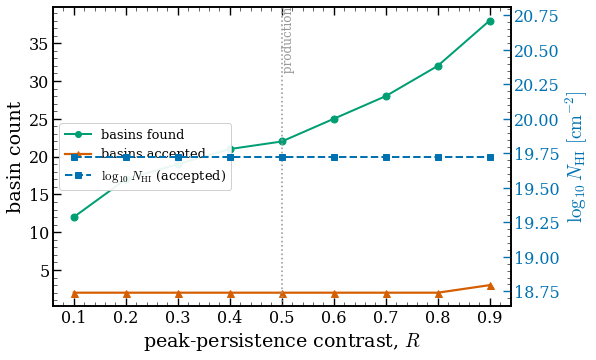

In [8]:
# =============================================================================
# CELL 7 -- FIG (plots/sensitivity_peak_contrast.png)
# =============================================================================
plt.close('all')
fig, ax1 = plt.subplots(figsize=(8.2, 5.4))
ax2 = ax1.twinx()

n_basins = [row['n_basins'] for row in contrast_rows]
n_acc = [row['n_accepted'] for row in contrast_rows]
logn_acc = [np.log10(row['accepted_nhi']) if row['accepted_nhi'] > 0 else np.nan
            for row in contrast_rows]

ax1.plot(PEAK_CONTRAST_GRID, n_basins, 'o-', color=OI["green"], lw=2.0, ms=7,
         label='basins found')
ax1.plot(PEAK_CONTRAST_GRID, n_acc, '^-', color=OI["vermillion"], lw=2.2,
         ms=7, label='basins accepted')
ax2.plot(PEAK_CONTRAST_GRID, logn_acc, 's--', color=OI["blue"], lw=2.0, ms=6,
         label=r'$\log_{10} N_{\rm HI}$ (accepted)')

ax1.axvline(PEAK_CONTRAST_PROD, color=OI["grey"], lw=1.6, ls=':')
ax1.text(PEAK_CONTRAST_PROD, ax1.get_ylim()[1], '  production', rotation=90,
         va='top', ha='left', fontsize=12, color=OI["grey"])

ax1.set_xlabel(r'peak-persistence contrast, $R$')
ax1.set_ylabel('basin count')
ax2.set_ylabel(r'$\log_{10} N_{\rm HI}\ [\mathrm{cm^{-2}}]$', color=OI["blue"])
ax2.tick_params(axis='y', colors=OI["blue"])

ax1.legend(
    [Line2D([], [], color=OI["green"], marker='o', lw=2.0),
     Line2D([], [], color=OI["vermillion"], marker='^', lw=2.2),
     Line2D([], [], color=OI["blue"], marker='s', lw=2.0, ls='--')],
    ['basins found', 'basins accepted', r'$\log_{10} N_{\rm HI}$ (accepted)'],
    loc='center left', fontsize=13)

ax1.grid(False)
for s in ax1.spines.values():
    s.set_linewidth(1.6)

out = os.path.join(PLOT_DIR, "sensitivity_peak_contrast.png")
fig.savefig(out, dpi=300, bbox_inches='tight')
if hasattr(fig.canvas, "header_visible"):
    fig.canvas.header_visible = False
print(f"saved {out}")
plt.show()
